id: notebooks/D_noise_sensitivity.ipynb

noise and sensitivity: radiometer equation, SEFD, noise of a visibility, S/N against integration time, bandwidth and baseline length, coherence and clocks, image noise

<!-- notebooks/D_noise_sensitivity.ipynb -- theory D: noise and sensitivity (Interferosim 0.9.3) -->
# D – Noise and sensitivity

---
  DI Erich Schubert, 07925151
  


*Theory notebook D.* How long must one integrate to see a source? The answer is the chain *system temperature → SEFD → noise of a visibility → S/N*, limited from the other side by the **coherence** of the two station clocks. Every formula is checked against a simulation with the package; the targets are the ones of the project – OH masers and Cygnus A on the 11.5 km baseline, the Sun with two horns.

Package: new in 0.9.3 `interferosim.instrument.sensitivity` – `antenna_temperature_k`, `radiometer_sigma_k`, `visibility_sigma_jy`, `integration_time_s`, `image_noise_jy`, `coherence_factor`, `phase_rms_white_fm_rad`, `coherence_time_s`, `random_walk_coherence`, `incoherent_snr`; further `Receiver.sefd_jy`, `quantization_efficiency`, the sky models and `Observation`.

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from interferosim.constants import C_LIGHT, HI_21CM, OH_1665
from interferosim.instrument import (Antenna, Receiver, Site, Station, Array, antenna_temperature_k, radiometer_sigma_k,
                                     visibility_sigma_jy, integration_time_s, image_noise_jy, coherence_factor,
                                     phase_rms_white_fm_rad, coherence_time_s, random_walk_coherence, incoherent_snr)
from interferosim.sky import SkyModel
from interferosim.observation import Observation
from interferosim.signal import quantization_efficiency

CFG = Path("..") / "configs"
DATE = "2026-11-01"
b210 = Receiver.from_toml(CFG / "receivers" / "b210.toml")
site = Site.from_toml(CFG / "sites" / "wilhelmsburg.toml")
ants = {n: Antenna.from_toml(CFG / "antennas" / f"{f}.toml") for n, f in (("horn 15 dBi", "horn_15dbi"), ("Yagi", "yagi"), ("dish 3 m", "dish_3m"))}
dish = ants["dish 3 m"]
target = Array(site, [Station.from_enu("W", site, 0, 0, 0, dish), Station.from_enu("X", site, 11_500, 0, 0, dish)],
               receiver=b210, name="project baseline 11.5 km")
B, TSYS = b210.bandwidth_hz, b210.t_sys_k
rng = np.random.default_rng(11)
print(f"B210 profile: T_sys = {TSYS:.0f} K (with external LNA), bandwidth {B / 1e6:.0f} MHz")

B210 profile: T_sys = 120 K (with external LNA), bandwidth 2 MHz


## 1. The radiometer equation

A receiver measures noise power. Averaging $N = B\,t$ independent samples of a noise signal of power $T_\mathrm{sys}$ (real samples: $2Bt$; complex samples at rate $B$: $Bt$ complex values with two components each) gives an estimate whose scatter is

$$\sigma_T = \frac{T_\mathrm{sys}}{\sqrt{B\,t}} .$$

A source raises the power by its antenna temperature $T_A = S A_\mathrm{eff}/2k$; it is detected when $T_A \gg \sigma_T$. Simulated: complex noise at 2 MS/s, the power averaged over $t$; the scatter of many such measurements against the formula.

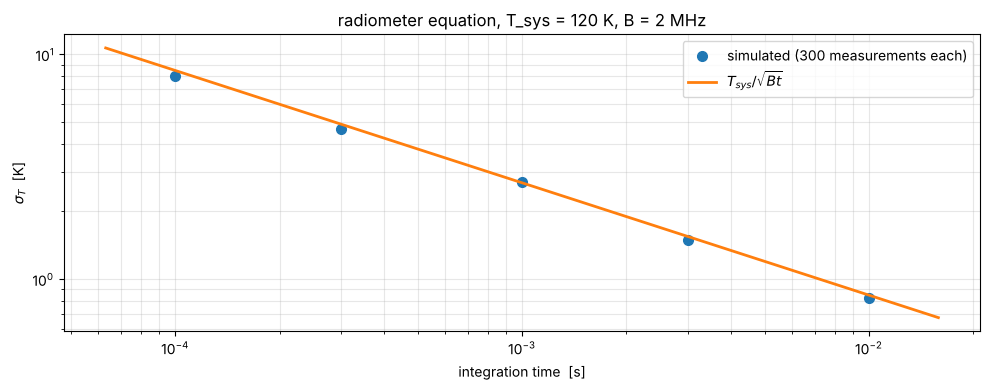

after 1 s: σ_T = 85 mK; after 1 h: 1.41 mK


In [2]:
fs = 2e6
ts = np.array([1e-4, 3e-4, 1e-3, 3e-3, 1e-2])
meas = []
for t in ts:
    n = int(fs * t)
    x = (rng.standard_normal((300, n)) + 1j * rng.standard_normal((300, n))) * np.sqrt(TSYS / 2)
    meas.append(np.std(np.mean(np.abs(x) ** 2, axis=1)))
fig, ax = plt.subplots(figsize=(10, 4))
ax.loglog(ts, meas, "o", ms=7, label="simulated (300 measurements each)")
tt = np.logspace(-4.2, -1.8, 50)
ax.loglog(tt, radiometer_sigma_k(TSYS, fs, tt), lw=2, label=r"$T_{sys}/\sqrt{Bt}$")
ax.set(xlabel="integration time  [s]", ylabel=r"$\sigma_T$  [K]", title=f"radiometer equation, T_sys = {TSYS:.0f} K, B = 2 MHz")
ax.grid(alpha=0.3, which="both"); ax.legend(); fig.tight_layout(); plt.show()
print(f"after 1 s: σ_T = {radiometer_sigma_k(TSYS, B, 1.0) * 1e3:.0f} mK; after 1 h: {radiometer_sigma_k(TSYS, B, 3600) * 1e3:.2f} mK")

## 2. SEFD and antenna temperature

The **system equivalent flux density** is the flux density of a source that would double the system temperature:

$$\mathrm{SEFD} = \frac{2k\,T_\mathrm{sys}}{A_\mathrm{eff}} .$$

It combines receiver and antenna in one number; the smaller, the better. With the B210 profile ($T_\mathrm{sys}$ = 120 K):

In [3]:
srcs = {"Sun (quiet, 21 cm)": 476_200, "Cas A": SkyModel.from_json(CFG / "skies" / "cas_a.json").total_flux_jy,
        "Cyg A": SkyModel.from_json(CFG / "skies" / "cyg_a.json").total_flux_jy, "OH maser M1": 70.0}
print(f"{'antenna':<13s} {'A_eff [m2]':>10s} {'SEFD [kJy]':>11s}   " + "   ".join(f"T_A {k} [K]" for k in srcs))
for name, a in ants.items():
    ae = a.effective_area(HI_21CM)
    sefd = b210.sefd_jy(a, HI_21CM)
    print(f"{name:<13s} {ae:10.3f} {sefd / 1e3:11.0f}   " + "   ".join(f"{antenna_temperature_k(s, ae):>{len(k) + 8}.3g}" for k, s in srcs.items()))

antenna       A_eff [m2]  SEFD [kJy]   T_A Sun (quiet, 21 cm) [K]   T_A Cas A [K]   T_A Cyg A [K]   T_A OH maser M1 [K]
horn 15 dBi        0.112        2956                         19.3          0.0664          0.0632               0.00284
Yagi               0.112        2956                         19.3          0.0664          0.0632               0.00284
dish 3 m           4.241          78                          731            2.51            2.39                 0.108


For all targets except the Sun, $T_A \ll T_\mathrm{sys}$: radio astronomy measures tiny excesses over the receiver noise. An interferometer helps here not by more area but by **correlation**: the receiver noises of two stations are independent and average out, only the common sky signal survives.

## 3. The noise of a visibility

Correlating two stations over $N = Bt$ complex samples gives a visibility whose real and imaginary parts each scatter by

$$\sigma_V = \sqrt{\frac{(\mathrm{SEFD}_1 + S_1)(\mathrm{SEFD}_2 + S_2)}{2\,B\,t}}\;\frac{1}{\eta_Q},$$

$S_k$ the source power received by station $k$ (negligible except for the Sun), $\eta_Q$ the quantisation efficiency (notebook C). Checked with two simulated station streams (receiver noise of SEFD power each, a common source of 5 % of it), correlated over $t$:

In [4]:
sefd = b210.sefd_jy(dish, HI_21CM)
S = 0.05 * sefd
fs = 2e6
print(f"{'t [ms]':>7s} {'sigma simulated [Jy]':>21s} {'formula [Jy]':>13s} {'mean Re V [Jy]':>15s} (true {S:.0f} Jy)")
for t in (0.5e-3, 2e-3, 8e-3):
    n = int(fs * t)
    vis = []
    for _ in range(400):
        s = (rng.standard_normal(n) + 1j * rng.standard_normal(n)) * np.sqrt(S / 2)
        a = s + (rng.standard_normal(n) + 1j * rng.standard_normal(n)) * np.sqrt(sefd / 2)
        b = s + (rng.standard_normal(n) + 1j * rng.standard_normal(n)) * np.sqrt(sefd / 2)
        vis.append(np.mean(a * np.conj(b)))
    vis = np.array(vis)
    print(f"{t * 1e3:7.1f} {np.std(vis.real):21.0f} {float(visibility_sigma_jy(sefd, sefd, fs, t, S, S)):13.0f} {np.mean(vis.real):15.0f}")

 t [ms]  sigma simulated [Jy]  formula [Jy]  mean Re V [Jy] (true 3906 Jy)
    0.5                  1785          1834            3734


    2.0                   926           917            3998


    8.0                   468           459            3907


## 4. S/N against integration time, bandwidth and baseline length

For a visibility of amplitude $|V|$ the vector average reaches $\mathrm{S/N} = |V|/\sigma_V$ after

$$t = \frac{(\mathrm{S/N})^2\,\mathrm{SEFD}_1\,\mathrm{SEFD}_2}{2\,B\,|V|^2\,\eta_Q^2} .$$

The decisive quantity is $|V|$ **at the baseline used**, not the total flux: a resolved source has lost most of its correlated flux. For the 11.5 km baseline the median $|V|$ over a 16 h track (from the sky models) enters, for the Sun the horns at 10 m (with the source term, because the Sun raises the system temperature).

target                         S total [Jy]  |V| [Jy]  SEFD [kJy]  t for S/N 10 (2 MHz, 12 bit)     2 bit
OH masers M1-M3, 3 m dishes             135      72.8          78                        28.8 s    37.1 s
Cyg A, 3 m dishes                      1556      29.9          78                       170.9 s   220.1 s
Cas A, 3 m dishes                      1636       1.3          78                        26.3 h    33.9 h
Sun, two horns 10 m                  476200  351658.3        2956                       2.38 ms   3.07 ms


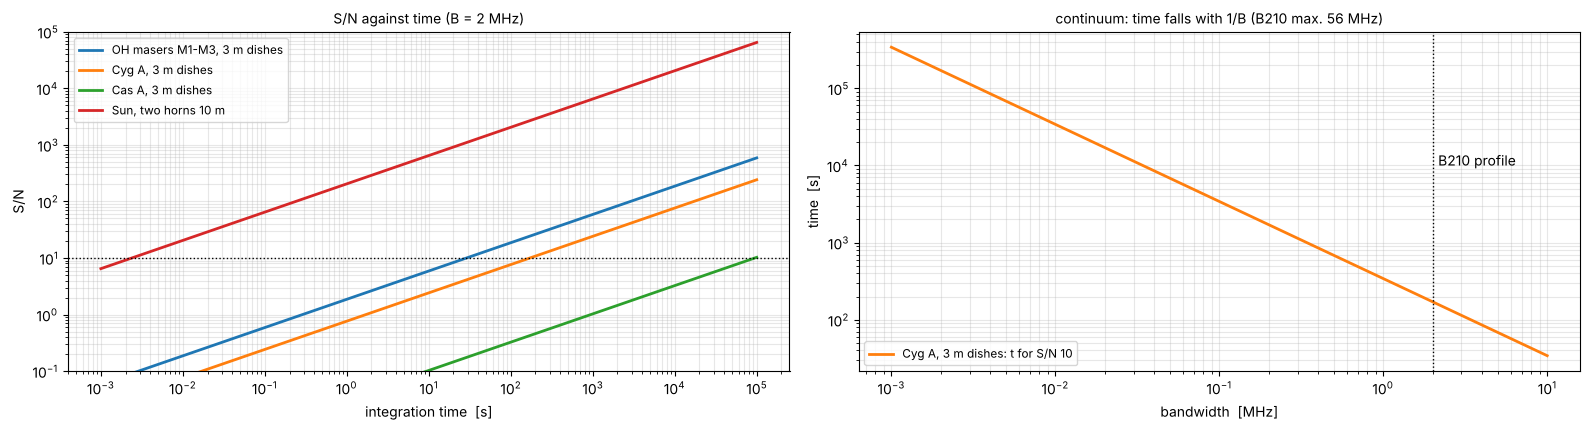

In [5]:
def median_vis(sky_file, freq, arr):
    sky = SkyModel.from_json(CFG / "skies" / sky_file)
    o = Observation.from_sky(sky, arr, ha_range_h=(-8, 8), t_int_s=300, freq_hz=freq, date=DATE)
    q = o.uvw()[0][o.visible()]
    return sky, float(np.median(np.abs(sky.visibility(q[:, 0], q[:, 1]))))
eta2 = quantization_efficiency(2)
rows = []
for label, f, fname, ant in (("OH masers M1-M3, 3 m dishes", OH_1665, "w3oh_masers.json", dish),
                             ("Cyg A, 3 m dishes", HI_21CM, "cyg_a.json", dish),
                             ("Cas A, 3 m dishes", HI_21CM, "cas_a.json", dish)):
    sky, v = median_vis(fname, f, target)
    se = b210.sefd_jy(ant, f)
    rows.append((label, sky.total_flux_jy, v, se, 0.0))
horn = ants["horn 15 dBi"]
sun = SkyModel.from_json(CFG / "skies" / "sun_21cm.json")
v_sun = abs(sun.components[0].visibility(np.array([10 / (C_LIGHT / HI_21CM)]), np.zeros(1))[0])
rows.append(("Sun, two horns 10 m", sun.total_flux_jy, v_sun, b210.sefd_jy(horn, HI_21CM), sun.total_flux_jy))
print(f"{'target':<30s} {'S total [Jy]':>12s} {'|V| [Jy]':>9s} {'SEFD [kJy]':>11s} {'t for S/N 10 (2 MHz, 12 bit)':>29s} {'2 bit':>9s}")
for label, stot, v, se, s_src in rows:
    t12 = float(integration_time_s(v, 10, se, se, B, 1.0, s_src, s_src))
    t2 = float(integration_time_s(v, 10, se, se, B, eta2, s_src, s_src))
    fmt = lambda t: f"{t * 1e3:.2f} ms" if t < 1 else (f"{t:.1f} s" if t < 600 else f"{t / 3600:.1f} h")
    print(f"{label:<30s} {stot:12.0f} {v:9.1f} {se / 1e3:11.0f} {fmt(t12):>29s} {fmt(t2):>9s}")
fig, axes = plt.subplots(1, 2, figsize=(16, 4.4))
tt = np.logspace(-3, 5, 200)
for (label, stot, v, se, s_src), col in zip(rows, ("C0", "C1", "C2", "C3")):
    axes[0].loglog(tt, v / visibility_sigma_jy(se, se, B, tt, s_src, s_src), color=col, lw=2, label=label)
axes[0].axhline(10, color="k", ls=":", lw=1)
axes[0].set(xlabel="integration time  [s]", ylabel="S/N", ylim=(0.1, 1e5), title="S/N against time (B = 2 MHz)")
bws = np.logspace(3, 7, 100)
lab, stot, v, se, _ = rows[1]
axes[1].loglog(bws / 1e6, integration_time_s(v, 10, se, se, bws), lw=2, color="C1", label=f"{lab}: t for S/N 10")
axes[1].axvline(2, color="k", ls=":", lw=1); axes[1].annotate("B210 profile", (2, 1e4), xytext=(4, 0), textcoords="offset points")
axes[1].set(xlabel="bandwidth  [MHz]", ylabel="time  [s]", title="continuum: time falls with 1/B (B210 max. 56 MHz)")
for ax in axes: ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8.5); ax.title.set_fontsize(10)
fig.tight_layout(); plt.show()

Cas A, the brightest continuum source in the sky, has almost no correlated flux left at 54 kλ (a shell of 5′); Cygnus A keeps its hotspots. On the project baseline the masers and the Cyg A hotspots need seconds to minutes in 2 MHz – *if* the phase stays coherent over that time (section 5). For the Sun with horns the S/N is reached within milliseconds; there the source itself dominates the noise.

## 5. Coherence: the clocks set the limit

The averaging of section 4 is coherent: the visibility phase must stay constant. With two independent clocks it does not. For white frequency noise, $\sigma_y(\tau) = \sigma_1/\sqrt\tau$ per clock, the phase difference performs a random walk,

$$\sigma_\varphi(T) = 2\pi f\,\sigma_1\sqrt{2T},$$

and a coherent average over $[0, T]$, with the phase referred to the middle of the interval (as a phase solution per segment does), keeps on average the fraction $4(1 - e^{-\sigma^2/4})/\sigma^2$ of the amplitude (`random_walk_coherence`, $\sigma = \sigma_\varphi(T)$); for a fixed Gaussian scatter it would be $e^{-\sigma^2/2}$ (`coherence_factor`). The **coherence time** is reached at $\sigma_\varphi$ = 1 rad. The values of $\sigma_1$ below are illustrative short-term stabilities of oscillator classes, not data-sheet values of particular devices.

clock                           sigma_y(1 s)   coherence time (1 rad, two clocks)
TCXO (free running)                    1e-09                           0.00628 s
OCXO                                   1e-11                              62.8 s
GPSDO (short term = its OCXO)          1e-11                              62.8 s
rubidium                               3e-12                               697 s
hydrogen maser                         1e-13                          6.28e+05 s


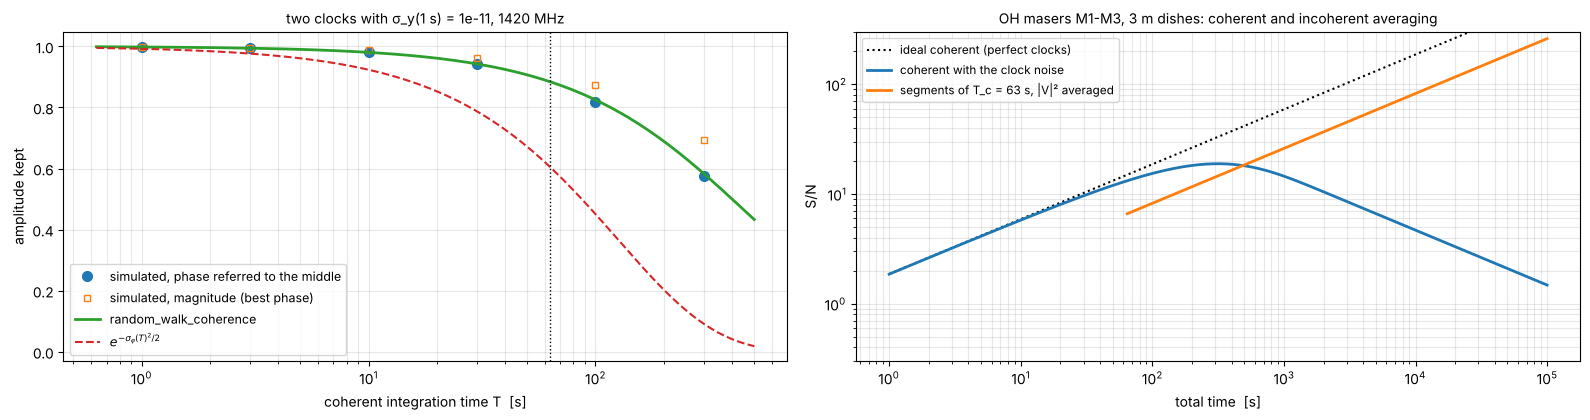

maser group, one segment of 63 s: S/N 13.1; incoherent after 1 h: 49.3, ideal coherent after 1 h: 112


In [6]:
f0 = HI_21CM
clocks = {"TCXO (free running)": 1e-9, "OCXO": 1e-11, "GPSDO (short term = its OCXO)": 1e-11, "rubidium": 3e-12, "hydrogen maser": 1e-13}
print(f"{'clock':<30s} {'sigma_y(1 s)':>13s} {'coherence time (1 rad, two clocks)':>36s}")
for name, s1 in clocks.items():
    tc = coherence_time_s(f0, s1)
    print(f"{name:<30s} {s1:13.0e} {tc:33.3g} s")
# simulation: random-walk phase of two OCXO-class clocks, coherent average over T
s1, dt = 1e-11, 0.05
Ts = np.array([1, 3, 10, 30, 100, 300])
sim = []
for T in Ts:
    n = int(T / dt)
    steps = rng.standard_normal((500, n)) * 2 * np.pi * f0 * s1 * np.sqrt(2 * dt)
    phi = np.cumsum(steps, axis=1)
    z = np.mean(np.exp(1j * (phi - phi[:, [n // 2]])), axis=1)      # phase referred to the middle
    sim.append((np.mean(z.real), np.mean(np.abs(z))))
sim = np.array(sim)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.3))
Tf = np.logspace(-0.2, 2.7, 200)
sig = phase_rms_white_fm_rad(f0, s1, Tf)
axes[0].semilogx(Ts, sim[:, 0], "o", ms=7, label="simulated, phase referred to the middle")
axes[0].semilogx(Ts, sim[:, 1], "s", ms=5, mfc="none", label="simulated, magnitude (best phase)")
axes[0].semilogx(Tf, random_walk_coherence(sig), lw=2, label="random_walk_coherence")
axes[0].semilogx(Tf, coherence_factor(sig), "--", lw=1.5, label=r"$e^{-\sigma_\varphi(T)^2/2}$")
axes[0].axvline(coherence_time_s(f0, s1), color="k", ls=":", lw=1)
axes[0].set(xlabel="coherent integration time T  [s]", ylabel="amplitude kept", title=f"two clocks with σ_y(1 s) = {s1:.0e}, 1420 MHz")
axes[0].legend(fontsize=9)
# coherent up to T_c, then incoherent
lab, stot, v, se, _ = rows[0]
t_tot = np.logspace(0, 5, 200)
tc = coherence_time_s(f0, s1)
snr_coh = v / visibility_sigma_jy(se, se, B, t_tot) * random_walk_coherence(phase_rms_white_fm_rad(f0, s1, t_tot))
seg = v / visibility_sigma_jy(se, se, B, tc) * float(random_walk_coherence(1.0))
snr_inc = np.where(t_tot > tc, incoherent_snr(seg, t_tot / tc), np.nan)
axes[1].loglog(t_tot, v / visibility_sigma_jy(se, se, B, t_tot), "k:", label="ideal coherent (perfect clocks)")
axes[1].loglog(t_tot, snr_coh, lw=2, label="coherent with the clock noise")
axes[1].loglog(t_tot, snr_inc, lw=2, label=f"segments of T_c = {tc:.0f} s, |V|² averaged")
axes[1].set(xlabel="total time  [s]", ylabel="S/N", ylim=(0.3, 300), title=f"{lab}: coherent and incoherent averaging")
axes[1].legend(fontsize=8.5)
for ax in axes: ax.grid(alpha=0.3, which="both"); ax.title.set_fontsize(10)
fig.tight_layout(); plt.show()
print(f"maser group, one segment of {tc:.0f} s: S/N {seg:.1f}; incoherent after 1 h: {float(incoherent_snr(seg, 3600 / tc)):.1f}, "
      f"ideal coherent after 1 h: {float(v / visibility_sigma_jy(se, se, B, 3600)):.0f}")

Beyond the coherence time the coherent S/N stops growing and falls again. Averaging the power $|V|^2$ of coherent segments still detects the source: with $n$ segments of S/N $s$ each, $\mathrm{S/N} = s^2\sqrt{n}/(2\sqrt{1+s^2})$ (`incoherent_snr`) – always below the coherent $s\sqrt{n}$, by a factor $s/2$ for weak segments – and the phase, the information needed for imaging, is lost. Hence the GPSDO: it keeps the frequencies on average together, but over seconds to minutes the short-term stability of its oscillator decides. Over the night, a fringe-rate solution per segment (notebook 05) removes the slow drift.

## 6. Image noise and the number of baselines

A naturally weighted image from $N_\mathrm{bl}$ equal baselines averages all visibilities; its noise is $\sigma_V/\sqrt{N_\mathrm{bl}}$ for the same time and bandwidth. With $N$ stations $N_\mathrm{bl} = N(N-1)/2$: three stations already triple the number of baselines.

In [7]:
print(f"{'stations':>8s} {'baselines':>10s} {'image noise, 8 h, 2 MHz, 3 m dishes':>36s} {'with 2-bit data':>16s}")
for n_st in (2, 3, 4, 6):
    nbl = n_st * (n_st - 1) // 2
    s12 = image_noise_jy(sefd, B, 8 * 3600, nbl)
    s2 = image_noise_jy(sefd, B, 8 * 3600, nbl, eta2)
    print(f"{n_st:8d} {nbl:10d} {s12 * 1e3:31.1f} mJy {s2 * 1e3:12.1f} mJy")
print("(notebook 06 measured 0.15 Jy/beam for 16 h of one-minute integrations of the project baseline at 1665 MHz,"
      f" where the formula gives {image_noise_jy(b210.sefd_jy(dish, OH_1665), B, 16 * 3600, 1):.3f} Jy for B = 2 MHz)")

stations  baselines  image noise, 8 h, 2 MHz, 3 m dishes  with 2-bit data
       2          1                           230.2 mJy        261.2 mJy
       3          3                           132.9 mJy        150.8 mJy
       4          6                            94.0 mJy        106.6 mJy
       6         15                            59.4 mJy         67.5 mJy
(notebook 06 measured 0.15 Jy/beam for 16 h of one-minute integrations of the project baseline at 1665 MHz, where the formula gives 0.163 Jy for B = 2 MHz)


## 7. Summary

**The formulas** – one chain from the receiver to the image, and the clock limit beside it:

| step | quantity | formula | grows / falls with | package | section |
|---|---|---|---|---|---|
| 1 | radiometer noise | $\sigma_T = T_\mathrm{sys}/\sqrt{Bt}$ | $1/\sqrt{Bt}$ | `radiometer_sigma_k` | 1 |
| 2 | antenna temperature, SEFD | $T_A = SA_\mathrm{eff}/2k$, $\mathrm{SEFD} = 2kT_\mathrm{sys}/A_\mathrm{eff}$ | $A_\mathrm{eff}$, $T_\mathrm{sys}$ | `antenna_temperature_k`, `Receiver.sefd_jy` | 2 |
| 3 | noise of a visibility | $\sigma_V = \sqrt{(\mathrm{SEFD}_1+S_1)(\mathrm{SEFD}_2+S_2)/2Bt}\,/\,\eta_Q$ | $1/\sqrt{Bt}$, bits via $\eta_Q$ | `visibility_sigma_jy` | 3 |
| 4 | time for a S/N | $t = (\mathrm{S/N})^2\,\mathrm{SEFD}_1\mathrm{SEFD}_2/(2B\,\lvert V\rvert^2\eta_Q^2)$ | $1/\lvert V\rvert^2$ – the correlated flux at the baseline, not the total flux | `integration_time_s` | 4 |
| 5 | clock phase | $\sigma_\varphi(T) = 2\pi f\sigma_1\sqrt{2T}$; coherence time at 1 rad | $\sigma_1^{-2}$, $f^{-2}$ | `phase_rms_white_fm_rad`, `coherence_time_s` | 5 |
| 6 | coherent loss | $4(1-e^{-\sigma^2/4})/\sigma^2$ (phase referred to the middle) | $\sigma_\varphi(T)$ | `random_walk_coherence` | 5 |
| 7 | incoherent detection | $s^2\sqrt n/(2\sqrt{1+s^2})$ for $n$ segments of S/N $s$ | always below the coherent $s\sqrt n$ | `incoherent_snr` | 5 |
| 8 | image noise | $\sigma_V/\sqrt{N_\mathrm{bl}}$, $N_\mathrm{bl} = N(N-1)/2$ | number of stations | `image_noise_jy` | 6 |

**The project values** – computed from the quantities of this notebook (B210 profile: $T_\mathrm{sys}$ = 120 K, $B$ = 2 MHz, 12 bits unless stated otherwise):

In [8]:
from IPython.display import Markdown, display

def fmt_t(t):
    return f"{t * 1e3:.1f} ms" if t < 1 else (f"{t:.0f} s" if t < 600 else (f"{t / 60:.0f} min" if t < 7200 else f"{t / 3600:.1f} h"))

sefd_h = b210.sefd_jy(ants["horn 15 dBi"], HI_21CM)
tc_ocxo = coherence_time_s(HI_21CM, 1e-11)
lab_m, _, v_m, se_m, _ = rows[0]
seg_m = v_m / float(visibility_sigma_jy(se_m, se_m, B, tc_ocxo)) * float(random_walk_coherence(1.0))
table = [
    ("1", "radiometer noise", "1 s / 1 h", f"{radiometer_sigma_k(TSYS, B, 1) * 1e3:.0f} mK / {radiometer_sigma_k(TSYS, B, 3600) * 1e3:.1f} mK"),
    ("2", "SEFD", "3 m dish / horn or Yagi (15 dBi)", f"{sefd / 1e3:.0f} kJy / {sefd_h / 1e6:.1f} MJy"),
    ("2", "antenna temperature", "Sun on horn / Cyg A on 3 m dish / maser M1 on 3 m dish",
     f"{antenna_temperature_k(476_200, ants['horn 15 dBi'].effective_area(HI_21CM)):.0f} K / "
     f"{antenna_temperature_k(1556, dish.effective_area(HI_21CM)):.1f} K / {antenna_temperature_k(70, dish.effective_area(HI_21CM)) * 1e3:.0f} mK"),
    ("3", "noise of a visibility", "two 3 m dishes, 1 s / 1 min / 1 h",
     " / ".join(f"{float(visibility_sigma_jy(sefd, sefd, B, t)):.{0 if t < 60 else 1}f} Jy" for t in (1, 60, 3600))),
]
for label, stot, v, se, s_src in rows:
    t12 = float(integration_time_s(v, 10, se, se, B, 1.0, s_src, s_src))
    t2 = float(integration_time_s(v, 10, se, se, B, eta2, s_src, s_src))
    table.append(("4", "time for S/N 10", f"{label}: correlated flux {v:,.{0 if v > 100 else 1}f} Jy of {stot:,.0f} Jy", f"{fmt_t(t12)} (2 bit: {fmt_t(t2)})"))
table += [
    ("5", "coherence time (1 rad)", "two clocks, σ_y(1 s) = 1e-11 (OCXO class), 1420 MHz", fmt_t(tc_ocxo)),
    ("5", "coherence time (1 rad)", "two clocks, σ_y(1 s) = 1e-9 (free-running TCXO)", fmt_t(coherence_time_s(HI_21CM, 1e-9))),
    ("6", "amplitude kept at the coherence time", "phase referred to the middle", f"{float(random_walk_coherence(1.0)):.3f}"),
    ("7", "S/N after 1 h", f"{lab_m}: ideal coherent / incoherent ({fmt_t(tc_ocxo)} segments)",
     f"{float(v_m / visibility_sigma_jy(se_m, se_m, B, 3600)):.0f} / {float(incoherent_snr(seg_m, 3600 / tc_ocxo)):.0f}"),
    ("8", "image noise, 8 h", "2 / 3 / 6 stations of 3 m dishes",
     " / ".join(f"{image_noise_jy(sefd, B, 8 * 3600, n * (n - 1) // 2) * 1e3:.0f} mJy" for n in (2, 3, 6))),
]
md_lines = ["| step | quantity | conditions | value |", "|---|---|---|---|"] + [f"| {a} | {b} | {c} | {d} |" for a, b, c, d in table]
display(Markdown("\n".join(md_lines)))

| step | quantity | conditions | value |
|---|---|---|---|
| 1 | radiometer noise | 1 s / 1 h | 85 mK / 1.4 mK |
| 2 | SEFD | 3 m dish / horn or Yagi (15 dBi) | 78 kJy / 3.0 MJy |
| 2 | antenna temperature | Sun on horn / Cyg A on 3 m dish / maser M1 on 3 m dish | 19 K / 2.4 K / 108 mK |
| 3 | noise of a visibility | two 3 m dishes, 1 s / 1 min / 1 h | 39 Jy / 5.0 Jy / 0.7 Jy |
| 4 | time for S/N 10 | OH masers M1-M3, 3 m dishes: correlated flux 72.8 Jy of 135 Jy | 29 s (2 bit: 37 s) |
| 4 | time for S/N 10 | Cyg A, 3 m dishes: correlated flux 29.9 Jy of 1,556 Jy | 171 s (2 bit: 220 s) |
| 4 | time for S/N 10 | Cas A, 3 m dishes: correlated flux 1.3 Jy of 1,636 Jy | 26.3 h (2 bit: 33.9 h) |
| 4 | time for S/N 10 | Sun, two horns 10 m: correlated flux 351,658 Jy of 476,200 Jy | 2.4 ms (2 bit: 3.1 ms) |
| 5 | coherence time (1 rad) | two clocks, σ_y(1 s) = 1e-11 (OCXO class), 1420 MHz | 63 s |
| 5 | coherence time (1 rad) | two clocks, σ_y(1 s) = 1e-9 (free-running TCXO) | 6.3 ms |
| 6 | amplitude kept at the coherence time | phase referred to the middle | 0.885 |
| 7 | S/N after 1 h | OH masers M1-M3, 3 m dishes: ideal coherent / incoherent (63 s segments) | 112 / 49 |
| 8 | image noise, 8 h | 2 / 3 / 6 stations of 3 m dishes | 230 mJy / 133 mJy / 59 mJy |

**Reading the table.** The receiver and the antennas set the noise per visibility (steps 1–3); the source structure decides how much flux is left to detect on 11.5 km (step 4 – Cas A, the brightest continuum source, is almost resolved out); the clocks decide how long the averaging may stay coherent (steps 5–7). With GPSDO-class clocks the targets of the project need seconds to minutes – about the coherence time, which is why the fringe solution is renewed per segment (notebook 05).

## 8. Selector

Antenna, source flux density at the baseline, bandwidth, number of bits, clock class and total time; *Run Interact* shows the S/N with ideal and with real clocks. (Needs a running kernel.)

In [9]:
import ipywidgets as widgets
from IPython.display import display

def run_sens(antenna, v_jy, bandwidth_mhz, bits, clock, t_total_h):
    a = ants[antenna]
    se = b210.sefd_jy(a, HI_21CM)
    bw = bandwidth_mhz * 1e6
    eta = quantization_efficiency(bits)
    s1 = clocks[clock]
    tc = coherence_time_s(HI_21CM, s1)
    t = np.logspace(-2, np.log10(t_total_h * 3600), 300)
    ideal = v_jy / visibility_sigma_jy(se, se, bw, t, eta_q=eta)
    real = ideal * random_walk_coherence(phase_rms_white_fm_rad(HI_21CM, s1, t))
    seg = v_jy / float(visibility_sigma_jy(se, se, bw, tc, eta_q=eta)) * float(random_walk_coherence(1.0))
    inc = np.where(t > tc, incoherent_snr(seg, t / tc), np.nan)
    fig, ax = plt.subplots(figsize=(11, 4.3))
    ax.loglog(t, ideal, "k:", label="ideal coherent"); ax.loglog(t, real, lw=2, label="coherent, real clocks")
    ax.loglog(t, inc, lw=2, label=f"incoherent segments of {tc:.3g} s")
    ax.axhline(5, color="C3", ls="--", lw=1)
    ax.set(xlabel="time  [s]", ylabel="S/N", title=f"{antenna}, SEFD {se / 1e3:.0f} kJy, |V| = {v_jy} Jy, {bandwidth_mhz} MHz, {bits} bit, {clock}")
    ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=9); fig.tight_layout(); plt.show()
    print(f"t for S/N 5 (ideal): {float(integration_time_s(v_jy, 5, se, se, bw, eta)):.3g} s; coherence time {tc:.3g} s")

display(widgets.interactive(
    run_sens, {"manual": True},
    antenna=widgets.Dropdown(options=list(ants), value="dish 3 m", description="antenna"),
    v_jy=widgets.FloatLogSlider(value=20, base=10, min=-1, max=5, description="|V| [Jy]"),
    bandwidth_mhz=widgets.FloatLogSlider(value=2, base=10, min=-2, max=1.75, description="B [MHz]"),
    bits=widgets.Dropdown(options=[1, 2, 3, 4, 8, 12], value=12, description="bits"),
    clock=widgets.Dropdown(options=list(clocks), value="GPSDO (short term = its OCXO)", description="clock"),
    t_total_h=widgets.FloatLogSlider(value=1, base=10, min=-2, max=1.5, description="total [h]"),
))

interactive(children=(Dropdown(description='antenna', index=2, options=('horn 15 dBi', 'Yagi', 'dish 3 m'), va…